# RQ3 Analysis: Word Count & Sentence Count

Compares the textual characteristics (word count, sentence count) of human-written vs. LLM-generated PR descriptions.

- Uses `nltk.sent_tokenize` to split descriptions into sentences.
- Compares across models and prompt context variations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import sent_tokenize
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp

nltk.download('punkt_tab', quiet=True)

# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## Helper Functions

In [2]:
def cliffs_delta(lst1, lst2):
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

## 1. Data Loading & Preparation

In [3]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'

df = pd.read_csv(csv_path)

# Map Variation Codes to Names
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}

df['Context_Name'] = df['variation'].map(variation_map)

# Normalize PR IDs
df['normalized_pr_id'] = df['pr_id'].astype(str)

# --- FILTERING: Keep only paired PRs ---
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: <StringArray>
['meta-llama/llama-3.1-70b-instruct',             'gpt-5-mini-2025-08-07',
         'Qwen/Qwen2.5-72B-Instruct']
Length: 3, dtype: str
Human entries: 308, AI entries: 5528


## 2. Compute Word Count & Sentence Count

In [4]:
def compute_text_metrics(text):
    """Compute word count and sentence count for a given text."""
    if pd.isna(text) or str(text).strip() == '':
        return pd.Series({'word_count': 0, 'sentence_count': 0})
    text = str(text)
    word_count = len(text.split())
    sentence_count = len(sent_tokenize(text))
    return pd.Series({'word_count': word_count, 'sentence_count': sentence_count})

# Apply to both subsets
human_df[['word_count', 'sentence_count']] = human_df['text'].apply(compute_text_metrics)
ai_df[['word_count', 'sentence_count']] = ai_df['text'].apply(compute_text_metrics)

# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})

print("Text metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
combined_df[['entry_type', 'model', 'text', 'word_count', 'sentence_count']].head(10)

Text metrics computed.
Combined dataset size: 5836


,entry_type,model,text,word_count,sentence_count
0,human,Human,Fixes #8873 \r\n\r\n\r\n<!-- \r\n- Go through ...,128,6
1,human,Human,"Implements #1516. Selected fields (`ISBN`, `UR...",24,3
2,human,Human,"Fixes #8108 \r\n\r\nTheoretically works, but n...",174,9
3,human,Human,Fixes #3905\r\n\r\n<!-- describe the changes y...,105,3
4,human,Human,Fixes #2676\r\n,2,1
5,human,Human,Fixes #8654\r\nThis allows for the right click...,166,8
6,human,Human,# Changed database structure: table names are ...,220,12
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,33,2
8,human,Human,Fixes #3584\r\n\r\n(No changelod needed as thi...,84,2
9,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,50,3


## 3. Descriptive Statistics: Human vs AI (Overall)

In [5]:
for metric in ['word_count', 'sentence_count']:
    print(f"\n{'='*60}")
    print(f"  {metric.replace('_', ' ').title()} — Descriptive Statistics")
    print(f"{'='*60}")

    stats = combined_df.groupby('source')[metric].describe()
    stats['median'] = combined_df.groupby('source')[metric].median()
    display(stats)

    # IQR breakdown
    for src in ['Human', 'AI']:
        vals = combined_df[combined_df['source'] == src][metric]
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        print(f"  {src}: Q1={q1:.0f}, Median={vals.median():.0f}, Q3={q3:.0f}, IQR={q3 - q1:.0f}")


  Word Count — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5528.0,99.101664,85.326876,3.0,41.0,69.0,135.00,1226.0,69.0
Human,308.0,113.162338,65.700482,2.0,65.0,107.5,158.25,308.0,107.5


  Human: Q1=65, Median=108, Q3=158, IQR=93
  AI: Q1=41, Median=69, Q3=135, IQR=94

  Sentence Count — Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5528.0,5.786541,4.989044,1.0,3.0,4.0,8.0,71.0,4.0
Human,308.0,5.850649,4.040161,1.0,3.0,5.0,9.0,19.0,5.0


  Human: Q1=3, Median=5, Q3=9, IQR=6
  AI: Q1=3, Median=4, Q3=8, IQR=5


## 4. Descriptive Statistics: By Model

In [6]:
for metric in ['word_count', 'sentence_count']:
    print(f"\n{'='*60}")
    print(f"  {metric.replace('_', ' ').title()} — By Model")
    print(f"{'='*60}")

    stats_by_model = combined_df.groupby('model')[metric].agg(
        ['count', 'mean', 'std', 'median',
         lambda x: x.quantile(0.25),
         lambda x: x.quantile(0.75)]
    )
    stats_by_model.columns = ['Count', 'Mean', 'Std', 'Median', 'Q1', 'Q3']
    stats_by_model['IQR'] = stats_by_model['Q3'] - stats_by_model['Q1']
    display(stats_by_model)


  Word Count — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,308,113.162338,65.700482,107.5,65.0,158.25,93.25
Qwen/Qwen2.5-72B-Instruct,1842,72.084691,39.542239,68.0,51.0,86.00,35.00
gpt-5-mini-2025-08-07,1842,187.655809,85.970732,177.0,127.0,235.00,108.00
meta-llama/llama-3.1-70b-instruct,1844,37.631236,23.270628,34.0,22.0,49.00,27.00



  Sentence Count — By Model


,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,308,5.850649,4.040161,5.0,3.0,9.0,6.0
Qwen/Qwen2.5-72B-Instruct,1842,4.116721,2.411486,4.0,3.0,5.0,2.0
gpt-5-mini-2025-08-07,1842,10.768187,5.292838,10.0,7.0,14.0,7.0
meta-llama/llama-3.1-70b-instruct,1844,2.478308,1.520369,2.0,1.0,3.0,2.0


## 5. Box Plots: Human vs AI

/tmp/ipykernel_160302/1904005333.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_160302/1904005333.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


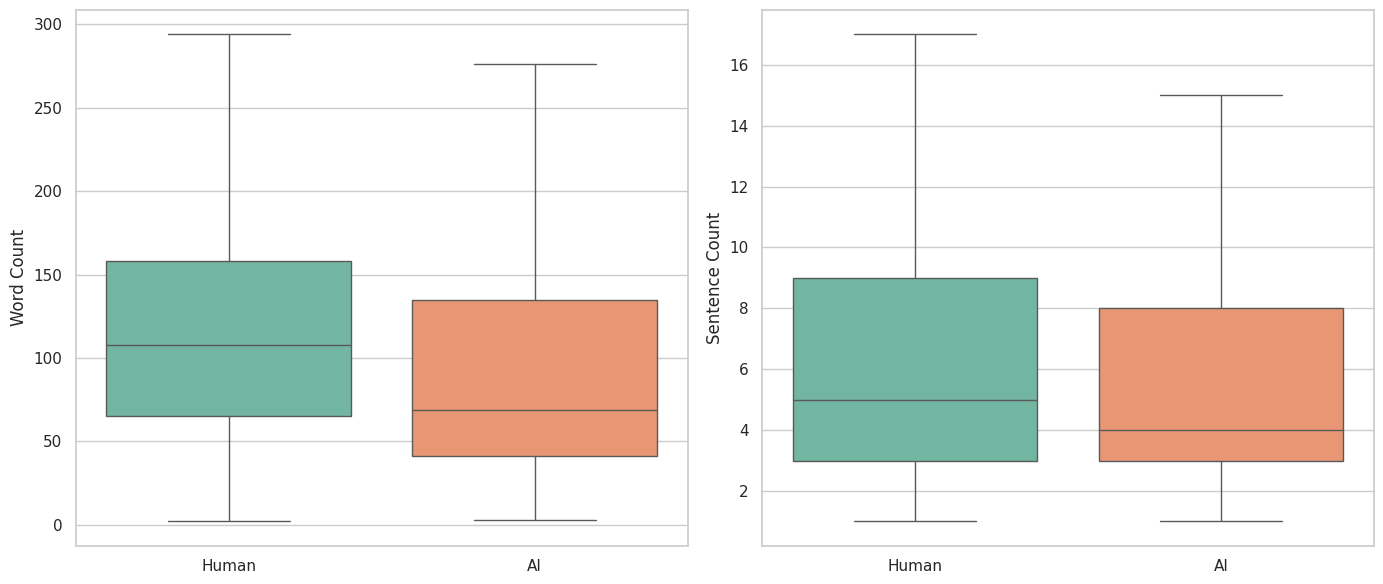

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for idx, metric in enumerate(['word_count', 'sentence_count']):
    ax = axes[idx]
    sns.boxplot(
        data=combined_df, x='source', y=metric, ax=ax,
        palette='Set2', showfliers=False
    )
    ax.set_xlabel('', fontsize=12)
    ax.set_ylabel(metric.replace('_', ' ').title(), fontsize=12)

plt.tight_layout()
plt.show()

## 6. Box Plots: By Model

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, metric in enumerate(['word_count', 'sentence_count']):
    ax = axes[idx]
    sns.boxplot(
        data=combined_df, x='model', y=metric, ax=ax,
        palette='Set3', showfliers=False
    )
    ax.set_xlabel('Model', fontsize=14)
    ax.set_ylabel(metric.replace('_', ' ').title(), fontsize=14)
    ax.tick_params(axis='x', rotation=25, labelsize=14)

plt.tight_layout()
plt.show()

## 7a. Word Count Boxplots by Context per LLM (with Human Baseline)

This view creates one graph per LLM model.

- Each graph contains 6 AI context boxplots.
- A Human baseline boxplot is added in the same graph for direct comparison.
- Human descriptions are context-independent, so they appear as a single `Human` category in each LLM panel.

In [ ]:
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

# Plot one panel per available LLM and include a Human baseline box in each panel.
llm_models = ai_df['model'].dropna().unique().tolist()

x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=14)

    ai_slice = ai_df[ai_df['model'] == model][['word_count', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['word_count']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['word_count', 'Category']],
        ai_slice[['word_count', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='word_count',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
    ax.set_ylabel('Word Count', fontsize=14)
    ax.tick_params(axis='x', rotation=30, labelsize=14)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'verbosity_word_count.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 7b. Sentence Count Boxplots by Context per LLM (with Human Baseline)

This mirrors the previous visualization for word count:

- One graph per LLM model.
- Each graph contains 6 AI context boxplots.
- A Human baseline sentence-count boxplot is included in each graph for direct comparison.

In [ ]:
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

# Plot one panel per available LLM and include a Human baseline box in each panel.
llm_models = ai_df['model'].dropna().unique().tolist()

x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=14)

    ai_slice = ai_df[ai_df['model'] == model][['sentence_count', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['sentence_count']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['sentence_count', 'Category']],
        ai_slice[['sentence_count', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='sentence_count',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
    ax.set_ylabel('Sentence Count', fontsize=14)
    ax.tick_params(axis='x', rotation=30, labelsize=14)

plt.tight_layout()
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'verbosity_sentence_count.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 8. Statistical Tests: Human vs AI (Mann-Whitney U)

In [11]:
results = []

for metric in ['word_count', 'sentence_count']:
    human_vals = combined_df[combined_df['source'] == 'Human'][metric].values
    ai_vals = combined_df[combined_df['source'] == 'AI'][metric].values

    stat, p = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
    cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())

    results.append({
        'Metric': metric.replace('_', ' ').title(),
        'Human Median': np.median(human_vals),
        'AI Median': np.median(ai_vals),
        'U-Statistic': stat,
        'p-value': p,
        'Significant': 'Yes' if p < 0.05 else 'No',
        "Cliff's Delta": round(cd, 4),
        'Effect Size': interpret_cliffs_delta(cd)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Metric,Human Median,AI Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,Word Count,107.5,69.0,1023003.5,2.429427e-09,Yes,0.2017,Small
1,Sentence Count,5.0,4.0,908264.0,4.635053e-02,Yes,0.0669,Negligible


## 9. Statistical Tests: Human vs Each Model (Mann-Whitney U)

In [12]:
model_results = []

human_wc = combined_df[combined_df['source'] == 'Human']['word_count'].values
human_sc = combined_df[combined_df['source'] == 'Human']['sentence_count'].values

for model in ai_df['model'].unique():
    model_data = ai_df[ai_df['model'] == model]

    for metric, human_vals in [('Word Count', human_wc), ('Sentence Count', human_sc)]:
        col = metric.lower().replace(' ', '_')
        ai_vals = model_data[col].values

        stat, p = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
        cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())

        model_results.append({
            'Model': model,
            'Metric': metric,
            'Human Mean': np.mean(human_vals),
            'Model Mean': np.mean(ai_vals),
            'Human Median': np.median(human_vals),
            'Model Median': np.median(ai_vals),
            'U-Statistic': stat,
            'p-value': p,
            'Significant': 'Yes' if p < 0.05 else 'No',
            "Cliff's Delta": round(cd, 4),
            'Effect Size': interpret_cliffs_delta(cd)
        })

model_results_df = pd.DataFrame(model_results)
display(model_results_df)

,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,Word Count,113.162338,37.631236,107.5,34.0,481720.0,1.845613e-85,Yes,0.6963,Large
1,meta-llama/llama-3.1-70b-instruct,Sentence Count,5.850649,2.478308,5.0,2.0,443137.5,1.019661e-58,Yes,0.5605,Large
2,gpt-5-mini-2025-08-07,Word Count,113.162338,187.655809,107.5,177.0,141232.0,2.683607e-45,Yes,-0.5021,Large
3,gpt-5-mini-2025-08-07,Sentence Count,5.850649,10.768187,5.0,10.0,125426.5,1.105097e-55,Yes,-0.5578,Large
4,Qwen/Qwen2.5-72B-Instruct,Word Count,113.162338,72.084691,107.5,68.0,400051.5,8.138611e-31,Yes,0.4103,Medium
5,Qwen/Qwen2.5-72B-Instruct,Sentence Count,5.850649,4.116721,5.0,4.0,339700.0,1.474246e-08,Yes,0.1975,Small


## 10. Kruskal-Wallis Test: Across All Models (including Human)

In [13]:
for metric in ['word_count', 'sentence_count']:
    print(f"\n{'='*60}")
    print(f"  Kruskal-Wallis Test: {metric.replace('_', ' ').title()}")
    print(f"{'='*60}")

    groups = [group[metric].values for name, group in combined_df.groupby('model')]
    stat, p = kruskal(*groups)
    print(f"  H-statistic: {stat:.4f}, p-value: {p:.6f}")
    print(f"  Significant: {'Yes' if p < 0.05 else 'No'}")

    if p < 0.05:
        print("\n  Post-hoc Dunn's Test (Bonferroni correction):")
        dunn = sp.posthoc_dunn(
            combined_df, val_col=metric, group_col='model', p_adjust='bonferroni'
        )
        display(dunn.round(4))


  Kruskal-Wallis Test: Word Count
  H-statistic: 3785.4134, p-value: 0.000000
  Significant: Yes

  Post-hoc Dunn's Test (Bonferroni correction):


,Human,Qwen/Qwen2.5-72B-Instruct,gpt-5-mini-2025-08-07,meta-llama/llama-3.1-70b-instruct
Human,1.0,0.0,0.0,0.0
Qwen/Qwen2.5-72B-Instruct,0.0,1.0,0.0,0.0
gpt-5-mini-2025-08-07,0.0,0.0,1.0,0.0
meta-llama/llama-3.1-70b-instruct,0.0,0.0,0.0,1.0



  Kruskal-Wallis Test: Sentence Count
  H-statistic: 3321.3206, p-value: 0.000000
  Significant: Yes

  Post-hoc Dunn's Test (Bonferroni correction):


,Human,Qwen/Qwen2.5-72B-Instruct,gpt-5-mini-2025-08-07,meta-llama/llama-3.1-70b-instruct
Human,1.0,0.0,0.0,0.0
Qwen/Qwen2.5-72B-Instruct,0.0,1.0,0.0,0.0
gpt-5-mini-2025-08-07,0.0,0.0,1.0,0.0
meta-llama/llama-3.1-70b-instruct,0.0,0.0,0.0,1.0


## 11. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for both word count and sentence count.

In [14]:
# ── Human vs. AI Context Variations: Cliff's δ per Model ──

model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

for metric in ['word_count', 'sentence_count']:
    print(f"\n{'='*90}")
    print(f"  Cliff's δ Effect Sizes: Human vs. AI Context Variations ({metric.replace('_', ' ').title()})")
    print(f"{'='*90}")

    rows = []
    for model in model_names:
        row = {'Model': model}
        for variation in variation_names:
            # AI values for this model + variation (only paired PRs)
            ai_vals = ai_df[
                (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
            ][metric].values

            # Human values for the same paired PRs
            human_vals = human_df[metric].values

            # Compute Cliff's delta
            delta = cliffs_delta(list(human_vals), list(ai_vals))
            interpretation = interpret_cliffs_delta(delta)

            # One-letter code for the interpretation
            code = interpretation
            row[variation] = f"{delta:.3f} ({code})"

        rows.append(row)

    result_df = pd.DataFrame(rows)
    result_df = result_df.set_index('Model')
    display(result_df)



  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Word Count)


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,0.787 (Large),0.787 (Large),0.715 (Large),0.590 (Large),0.690 (Large),0.607 (Large)
gpt-5-mini-2025-08-07,-0.586 (Large),-0.622 (Large),-0.311 (Small),-0.635 (Large),-0.312 (Small),-0.549 (Large)
Qwen/Qwen2.5-72B-Instruct,0.559 (Large),0.671 (Large),0.408 (Medium),0.192 (Small),0.370 (Medium),0.259 (Small)



  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Sentence Count)


,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,0.660 (Large),0.817 (Large),0.616 (Large),0.501 (Large),0.445 (Medium),0.323 (Small)
gpt-5-mini-2025-08-07,-0.624 (Large),-0.692 (Large),-0.388 (Medium),-0.586 (Large),-0.432 (Medium),-0.626 (Large)
Qwen/Qwen2.5-72B-Instruct,0.331 (Medium),0.599 (Large),0.204 (Small),0.005 (Negligible),0.057 (Negligible),-0.015 (Negligible)


## 12. Summary Table

In [15]:
summary_rows = []

for metric in ['word_count', 'sentence_count']:
    for model in combined_df['model'].unique():
        vals = combined_df[combined_df['model'] == model][metric]
        summary_rows.append({
            'Model': model,
            'Metric': metric.replace('_', ' ').title(),
            'N': len(vals),
            'Mean': round(vals.mean(), 2),
            'Median': round(vals.median(), 2),
            'Std': round(vals.std(), 2),
            'Min': vals.min(),
            'Max': vals.max(),
            'Q1': round(vals.quantile(0.25), 2),
            'Q3': round(vals.quantile(0.75), 2)
        })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# Save summary to CSV
summary_df.to_csv('outputs/rq3_word_sentence_count_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_word_sentence_count_summary.csv")

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Word Count,308,113.16,107.5,65.70,2,308,65.0,158.25
1,meta-llama/llama-3.1-70b-instruct,Word Count,1844,37.63,34.0,23.27,3,249,22.0,49.00
2,gpt-5-mini-2025-08-07,Word Count,1842,187.66,177.0,85.97,29,559,127.0,235.00
3,Qwen/Qwen2.5-72B-Instruct,Word Count,1842,72.08,68.0,39.54,18,1226,51.0,86.00
4,Human,Sentence Count,308,5.85,5.0,4.04,1,19,3.0,9.00
5,meta-llama/llama-3.1-70b-instruct,Sentence Count,1844,2.48,2.0,1.52,1,24,1.0,3.00
6,gpt-5-mini-2025-08-07,Sentence Count,1842,10.77,10.0,5.29,1,33,7.0,14.00
7,Qwen/Qwen2.5-72B-Instruct,Sentence Count,1842,4.12,4.0,2.41,1,71,3.0,5.00



Summary saved to outputs/rq3_word_sentence_count_summary.csv
